<img src="./logo_UNSAM.jpg" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº 5 - Estimación espectral: Ancho de banda de señales reales
#### HOFFENREICH JULIETA


# Introducción
En este trabajo se estimó la **densidad espectral de potencia (PSD)** de distintas señales reales. Se estudió cómo se distribuyó la potencia de cada señal en frecuencia y, posteriormente, se estimó su **ancho de banda**.

Para estimar la PSD se analizaron inicialmente tres métodos: **periodograma modificado, método de Welch y método de Blackman-Tukey**.

El **periodograma modificado** consiste en aplicar una ventana a la señal antes de calcular su transformada de Fourier. El ventaneo permite controlar el desparramo espectral, aunque modifica la resolución en frecuencia según la ventana utilizada. Para su implementación se utilizó la función `periodogram` de la librería `scipy.signal`. Sin embargo, este estimador presenta una varianza elevada que no tiende a cero al aumentar la cantidad de muestras, por lo que no es un estimador consistente de la PSD. Por este motivo, luego de analizar inicialmente su comportamiento sobre el ECG, para las señales restantes se continuó trabajando únicamente con **Welch y Blackman-Tukey**, ya que estos métodos permitieron reducir la varianza de la estimación.

El **método de Welch** consiste en dividir la señal en segmentos con solapamiento, calcular el periodograma de cada uno y luego promediarlos. De esta manera se logró reducir la varianza de la estimación. Sin embargo, se presenta un compromiso entre varianza y resolución: al aumentar la cantidad de promedios se utilizaron segmentos más cortos, disminuyendo la varianza pero también la resolución en frecuencia. Por lo tanto, para cada señal se seleccionó la **mayor cantidad de promedios posible sin perder picos relevantes**. El método se implementó mediante la función `welch` de la librería `scipy.signal`, utilizando una ventana Hann y un solapamiento del 50 % entre segmentos.

El **método de Blackman-Tukey** estima la PSD a partir de la transformada de Fourier de una versión ventaneada de la autocorrelación de la señal. En este caso, el parámetro $M$, asociado a la cantidad de retardos considerados, permitió controlar el compromiso entre resolución y varianza. Al disminuir $M$ se obtuvo una estimación más suavizada y de menor varianza, pero también de menor resolución. Por este motivo, se seleccionó para cada señal un valor de $M$ que permitiera reducir la varianza sin perder información espectral relevante. Como `scipy.signal` no dispone de una función directa para realizar esta estimación mediante Blackman-Tukey, se implementó una función propia basada en el código provisto en `pdstestbench`, utilizando una ventana Blackman sobre la autocorrelación.

Una vez seleccionados los parámetros de cada estimador, se determinó el **ancho de banda a partir de la potencia espectral acumulada**, considerando como banda significativa aquella que contenía el **99 % de la potencia total de la señal**.

Para las señales de **ECG y PPG**, cuyo contenido de interés se encontró concentrado desde las bajas frecuencias, se fijó el límite inferior en:

$$f_{\mathrm{inf}}=0$$

y se determinó la frecuencia superior necesaria para acumular el 99 % de la potencia. Por lo tanto:

$$BW=f_{\mathrm{sup}}$$

En cambio, para las **señales de audio** no se fijó previamente la frecuencia inferior. Se determinaron tanto $f_{\mathrm{inf}}$ como $f_{\mathrm{sup}}$, buscando el intervalo de menor ancho que contuviera el 99 % de la potencia espectral. El ancho de banda se calculó entonces como:

$$BW=f_{\mathrm{sup}}-f_{\mathrm{inf}}$$

De esta manera, el análisis permitió comparar el comportamiento de los distintos estimadores, estudiar el compromiso entre **varianza y resolución espectral** y determinar la región de frecuencias en la que se concentró la mayor parte de la potencia de cada señal.

# Análisis y Resultados
## Electrocardiograma (ECG)
En primer lugar se analizó la señal de **ECG sin ruido** tanto en el dominio temporal como en frecuencia. La PSD se estimó inicialmente mediante **Welch, periodograma modificado y Blackman-Tukey**.

Para Welch y Blackman-Tukey se probaron distintos parámetros buscando reducir la varianza sin perder picos relevantes. A partir de la comparación visual se seleccionaron **30 promedios** para Welch, utilizando una **ventana Hann**, y **$M=2000$** para Blackman-Tukey.

Finalmente, se graficó la señal en el dominio temporal junto con las tres estimaciones de la PSD y se calculó el ancho de banda correspondiente al 99 % de la potencia espectral. Como el contenido del ECG se concentró desde las bajas frecuencias, se tomó: $f_{\mathrm{inf}}=0\text{ Hz}$. 
Por lo tanto, el ancho de banda quedó determinado únicamente por la frecuencia superior:

$$BW=f_{\mathrm{sup}}$$

Cantidad de muestras: 30000
Duración: 30.0 s
Welch - cantidad de promedios: 30


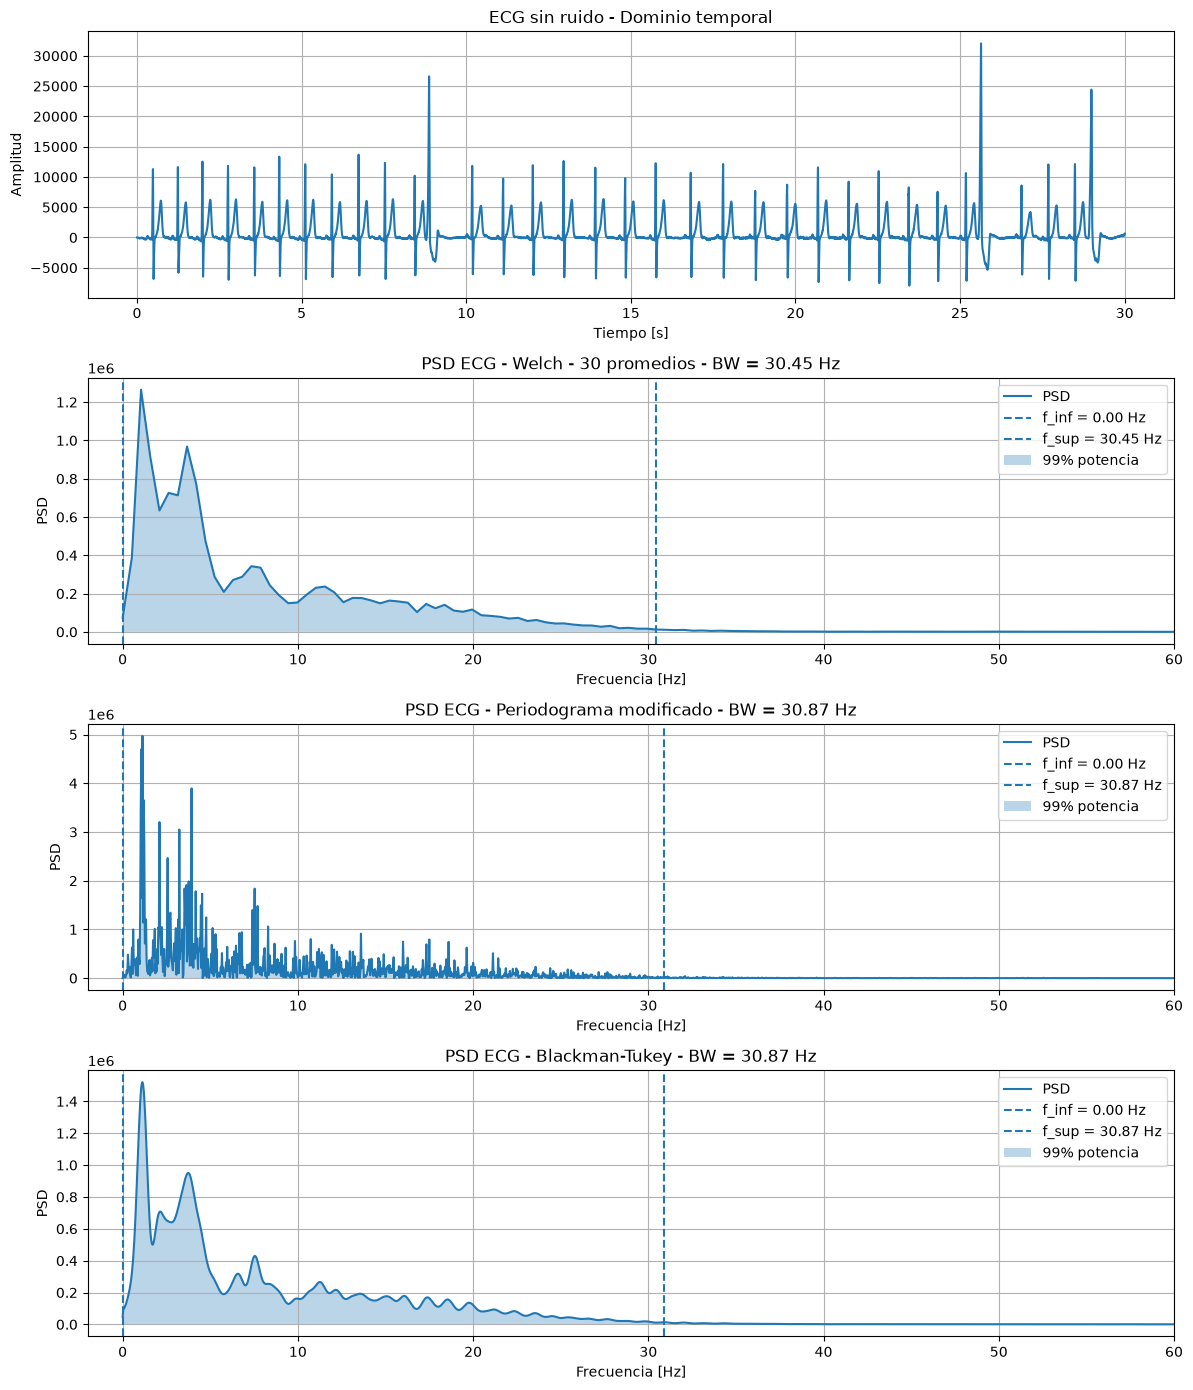

In [5]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
import scipy.io as sio

plt.close('all')

#%%FUNCIONES 

def ancho_banda_ecg(f, Pxx, porcentaje=0.99):
    """Calcula la frecuencia superior que contiene el porcentaje
    Para ECG consideramos:f_inf = 0 Hz
        BW = f_sup"""
    df = f[1] - f[0]
    # Potencia acumulada
    potencia_acum = np.cumsum(Pxx) * df
    # Normalización
    potencia_acum = potencia_acum / potencia_acum[-1]
    # Primer punto donde se alcanza el porcentaje deseado
    j = np.where(potencia_acum >= porcentaje)[0][0]
    f_inf = 0
    f_sup = f[j]
    BW = f_sup - f_inf

    return BW, f_inf, f_sup, 0, j

def blackman_tukey(x, fs, M=None, nfft=None):
    x = np.asarray(x).ravel()
    N = len(x)
    if M is None:
        M = N // 5

    if nfft is None:
        nfft = N

    # Quitamos la media, de forma coherente con
    # periodogram() y welch()
    x = x - np.mean(x)

    # Autocorrelación de TODA la señal
    r_full = sig.correlate(x,x,mode='full',method='fft') / N
    # Lag cero
    centro = N - 1
    # Nos quedamos con los lags entre -M y +M
    r = r_full[centro-M : centro+M+1]
    # Ventaneamos la autocorrelación
    ventana = sig.windows.blackman(len(r))
    r_vent = r * ventana
    # Acomodamos los lags para realizar la FFT
    r_fft = np.zeros(nfft)
    r_fft[:M+1] = r_vent[M:]  # lag 0 ... +M
    r_fft[-M:] = r_vent[:M]    # lag -M ... -1
    Pxx = np.abs(np.fft.rfft(r_fft)) / fs# Transformada de Fourier de la autocorrelación
    # PSD unilateral
    if nfft % 2 == 0:
        Pxx[1:-1] *= 2
    else:
        Pxx[1:] *= 2
    f = np.fft.rfftfreq(nfft, d=1/fs)
    return f, Pxx

#FUNCION ANCHO DE BANDA PARA AUDIO
def ancho_banda_audio(f, Pxx, porcentaje=0.99):

    df = f[1] - f[0]
    potencia = Pxx * df

    potencia_total = np.sum(potencia)
    objetivo = porcentaje * potencia_total

    acum = np.concatenate(([0], np.cumsum(potencia)))

    mejor_BW = np.inf
    mejor_i = 0
    mejor_j = len(f)-1

    for i in range(len(f)):

        objetivo_j = acum[i] + objetivo
        j = np.searchsorted(acum, objetivo_j)

        if j > len(f):
            break

        j = j - 1

        BW = f[j] - f[i]

        if BW < mejor_BW:
            mejor_BW = BW
            mejor_i = i
            mejor_j = j

    f_inf = f[mejor_i]
    f_sup = f[mejor_j]
    BW = f_sup - f_inf

    return BW, f_inf, f_sup, mejor_i, mejor_j
##################
#%% ECG
##################
# Lectura de ECG #
fs_ecg = 1000  # Hz

##################
# ECG sin ruido  #
##################

ecg_one_lead = np.load('ecg_sin_ruido.npy')

N = len(ecg_one_lead)
t_ecg = np.arange(N) / fs_ecg
print('Cantidad de muestras:', N)
print('Duración:', N/fs_ecg, 's')


#%%PSD ECG - Welch elegido: 30 promedios   #

nperseg_ecg = 1905
noverlap_ecg = nperseg_ecg // 2

f_welch_ecg, Pxx_welch_ecg = sig.welch(ecg_one_lead,fs=fs_ecg,window='hann',nperseg=nperseg_ecg,noverlap=noverlap_ecg,
    scaling='density')
K = 1 + (N - nperseg_ecg) // (nperseg_ecg - noverlap_ecg)
print('Welch - cantidad de promedios:', K)
BW_welch_ecg, f_welch_inf, f_welch_sup, \
i_welch, j_welch = ancho_banda_ecg(f_welch_ecg,Pxx_welch_ecg)

#%% PSD ECG - PERIODOGRAMA MODIFICADO


f_per_ecg, Pxx_per_ecg = sig.periodogram(ecg_one_lead,fs=fs_ecg,scaling='density')

BW_per_ecg, f_per_inf, f_per_sup, \
i_per, j_per = ancho_banda_ecg(f_per_ecg,Pxx_per_ecg)

#%% PSD ECG - BLACKMAN TUKEY

M_ecg = 2000
f_bt_ecg, Pxx_bt_ecg = blackman_tukey(ecg_one_lead,fs=fs_ecg, M=M_ecg,nfft=N)

BW_bt_ecg, f_bt_inf, f_bt_sup, \
i_bt, j_bt = ancho_banda_ecg(f_bt_ecg,Pxx_bt_ecg)

#%% FIGURA COMPARATIVA ECG

fig, axs = plt.subplots(4, 1, figsize=(12, 14))

# Señal temporal
axs[0].plot(t_ecg, ecg_one_lead)
axs[0].set_title('ECG sin ruido - Dominio temporal')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].grid()

# Welch
axs[1].plot(f_welch_ecg, Pxx_welch_ecg, label='PSD')
axs[1].axvline(f_welch_inf, ls='--', label=f'f_inf = {f_welch_inf:.2f} Hz')
axs[1].axvline(f_welch_sup, ls='--', label=f'f_sup = {f_welch_sup:.2f} Hz')
axs[1].fill_between(f_welch_ecg[i_welch:j_welch+1], Pxx_welch_ecg[i_welch:j_welch+1], alpha=0.3, label='99% potencia')
axs[1].set_title(f'PSD ECG - Welch - 30 promedios - BW = {BW_welch_ecg:.2f} Hz')
axs[1].set_xlim(-2, 60)
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('PSD')
axs[1].grid()
axs[1].legend()

# Periodograma modificado
axs[2].plot(f_per_ecg, Pxx_per_ecg, label='PSD')
axs[2].axvline(f_per_inf, ls='--', label=f'f_inf = {f_per_inf:.2f} Hz')
axs[2].axvline(f_per_sup, ls='--', label=f'f_sup = {f_per_sup:.2f} Hz')
axs[2].fill_between(f_per_ecg[i_per:j_per+1], Pxx_per_ecg[i_per:j_per+1], alpha=0.3, label='99% potencia')
axs[2].set_title(f'PSD ECG - Periodograma modificado - BW = {BW_per_ecg:.2f} Hz')
axs[2].set_xlim(-2, 60)
axs[2].set_xlabel('Frecuencia [Hz]')
axs[2].set_ylabel('PSD')
axs[2].grid()
axs[2].legend()

# Blackman-Tukey
axs[3].plot(f_bt_ecg, Pxx_bt_ecg, label='PSD')
axs[3].axvline(f_bt_inf, ls='--', label=f'f_inf = {f_bt_inf:.2f} Hz')
axs[3].axvline(f_bt_sup, ls='--', label=f'f_sup = {f_bt_sup:.2f} Hz')
axs[3].fill_between(f_bt_ecg[i_bt:j_bt+1], Pxx_bt_ecg[i_bt:j_bt+1], alpha=0.3, label='99% potencia')
axs[3].set_title(f'PSD ECG - Blackman-Tukey - BW = {BW_bt_ecg:.2f} Hz')
axs[3].set_xlim(-2, 60)
axs[3].set_xlabel('Frecuencia [Hz]')
axs[3].set_ylabel('PSD')
axs[3].grid()
axs[3].legend()

plt.tight_layout()
plt.show()

En principio, notamos que los tres métodos determinaron valores muy similares para el límite superior del ancho de banda, por lo que identificaron de manera semejante la región en la que se concentró el 99 % de la potencia.

La principal diferencia se observó en la forma de las estimaciones. El periodograma modificado presentó grandes fluctuaciones entre bins de frecuencia, evidenciando su elevada varianza, mientras que Welch y Blackman-Tukey produjeron estimaciones considerablemente más suaves, conservando los principales picos del espectro.

También se observó una diferencia en la escala vertical entre Welch y el periodograma modificado. Esto se debió a que Welch calculó y promedió los periodogramas de varios segmentos parcialmente solapados, reduciendo las fluctuaciones y distribuyendo la potencia de manera más suave entre las frecuencias. El periodograma modificado, en cambio, se obtuvo a partir de un único periodograma de la señal ventaneada, por lo que presentó mayor resolución pero también mayor varianza.

Por este motivo, para las señales restantes se continuó trabajando únicamente con Welch y Blackman-Tukey, ya que ambos permitieron reducir la varianza de la estimación y obtener estimaciones más estables.

## Señal fotopletismográfica (PPG)
Posteriormente se analizó la señal **PPG sin ruido**, utilizando únicamente los métodos de Welch y Blackman-Tukey.

Al igual que para el ECG, se probaron distintas cantidades de promedios para Welch y diferentes valores de $M$ para Blackman-Tukey, buscando disminuir la varianza de la estimación sin perder información relevante. Para Welch se utilizó una ventana Hann y se seleccionaron **32 promedios**, mientras que para Blackman-Tukey se seleccionó **$M=1122$**.

Una vez definidos estos parámetros, se graficó la señal en el dominio temporal y las estimaciones de la PSD obtenidas mediante ambos métodos. Siguiendo el criterio definido previamente para este tipo de señales, se consideró $f_{\mathrm{inf}}=0$ Hz y se determinó la frecuencia superior necesaria para contener el 99 % de la potencia espectral.


PPG
Cantidad de muestras: 44919
Duración: 112.2975 s


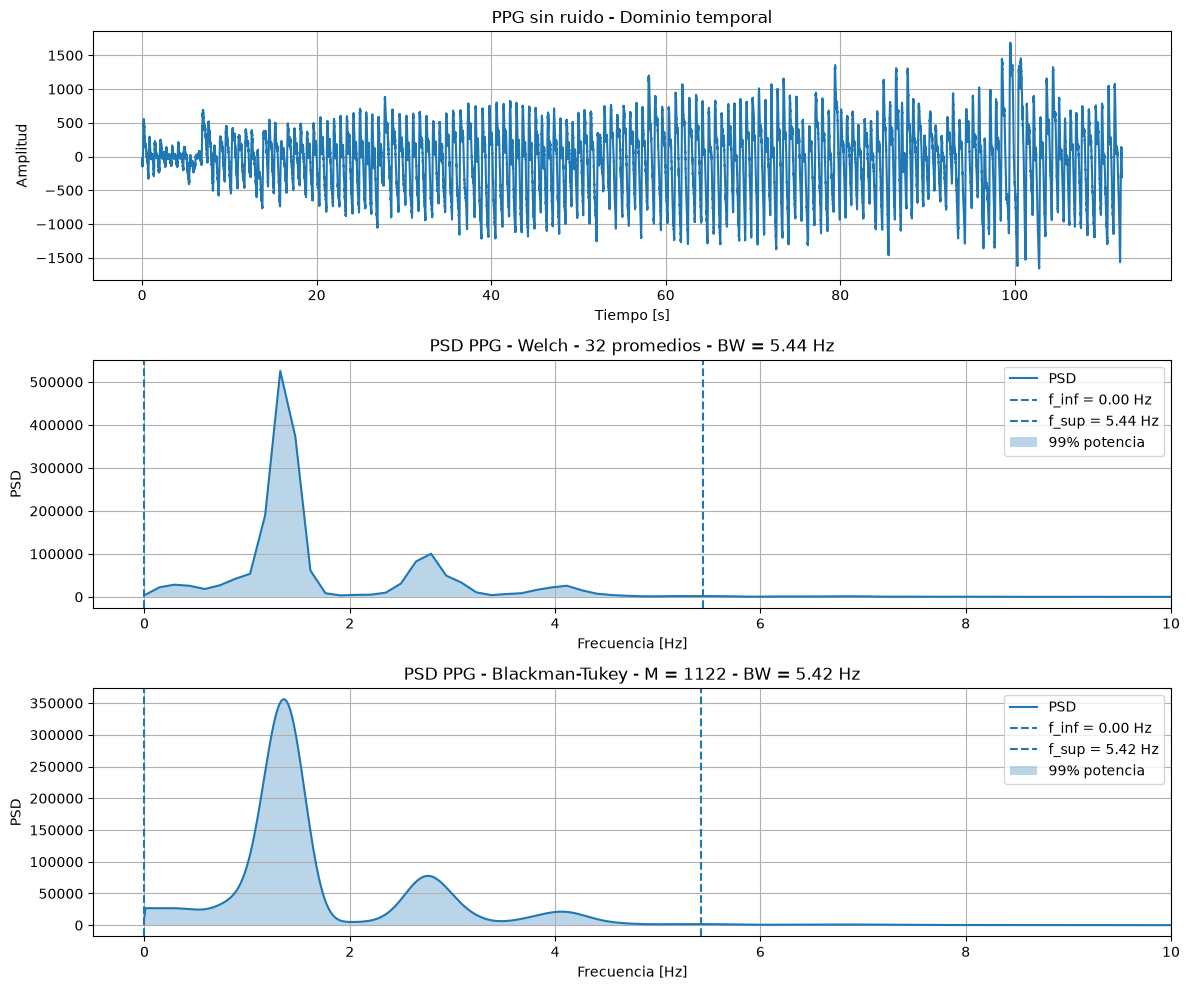

In [6]:
#%% PPG 2DA SENAL
####################################
# Lectura de pletismografía (PPG)  #
####################################
fs_ppg = 400  # Hz
ppg = np.load('ppg_sin_ruido.npy')

N_ppg = len(ppg)
t_ppg = np.arange(N_ppg) / fs_ppg

print('\nPPG')
print('Cantidad de muestras:', N_ppg)
print('Duración:', N_ppg/fs_ppg, 's')


def nperseg_para_promedios(N, K_deseado):
    posibles = []
    for nperseg in range(2, N+1):
        noverlap = nperseg // 2
        K = 1 + (N - nperseg) // (nperseg - noverlap)
        if K == K_deseado:
            posibles.append(nperseg)
    return max(posibles) if posibles else None

#%% PPG - WELCH DEFINITIVO: 32 PROMEDIOS

nperseg_ppg = nperseg_para_promedios(N_ppg, 32)
noverlap_ppg = nperseg_ppg // 2

f_welch_ppg, Pxx_welch_ppg = sig.welch(
    ppg,fs=fs_ppg,window='hann',nperseg=nperseg_ppg,noverlap=noverlap_ppg,scaling='density')

K_ppg = 1 + (N_ppg-nperseg_ppg)//(nperseg_ppg-noverlap_ppg)



BW_welch_ppg, f_welch_ppg_inf, f_welch_ppg_sup, \
i_welch_ppg, j_welch_ppg = ancho_banda_ecg(
    f_welch_ppg, Pxx_welch_ppg)

#%% PPG - BLACKMAN TUKEY DEFINITIVO

M_ppg = 1122
f_bt_ppg, Pxx_bt_ppg = blackman_tukey(ppg,fs=fs_ppg,M=M_ppg,nfft=N_ppg)

BW_bt_ppg, f_bt_ppg_inf, f_bt_ppg_sup, \
i_bt_ppg, j_bt_ppg = ancho_banda_ecg(f_bt_ppg, Pxx_bt_ppg)


#%% FIGURA FINAL PPG

fig, axs = plt.subplots(3, 1, figsize=(12, 10))

# Señal temporal
axs[0].plot(t_ppg, ppg)
axs[0].set_title('PPG sin ruido - Dominio temporal')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].grid()

# Welch
axs[1].plot(f_welch_ppg, Pxx_welch_ppg, label='PSD')
axs[1].axvline(f_welch_ppg_inf, ls='--',
               label=f'f_inf = {f_welch_ppg_inf:.2f} Hz')
axs[1].axvline(f_welch_ppg_sup, ls='--',
               label=f'f_sup = {f_welch_ppg_sup:.2f} Hz')
axs[1].fill_between(
    f_welch_ppg[i_welch_ppg:j_welch_ppg+1],
    Pxx_welch_ppg[i_welch_ppg:j_welch_ppg+1],
    alpha=0.3, label='99% potencia'
)
axs[1].set_title(
    f'PSD PPG - Welch - {K_ppg} promedios - BW = {BW_welch_ppg:.2f} Hz'
)
axs[1].set_xlim(-0.5, 10)
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('PSD')
axs[1].grid()
axs[1].legend()

# Blackman-Tukey
axs[2].plot(f_bt_ppg, Pxx_bt_ppg, label='PSD')
axs[2].axvline(f_bt_ppg_inf, ls='--',
               label=f'f_inf = {f_bt_ppg_inf:.2f} Hz')
axs[2].axvline(f_bt_ppg_sup, ls='--',
               label=f'f_sup = {f_bt_ppg_sup:.2f} Hz')
axs[2].fill_between(
    f_bt_ppg[i_bt_ppg:j_bt_ppg+1],
    Pxx_bt_ppg[i_bt_ppg:j_bt_ppg+1],
    alpha=0.3, label='99% potencia'
)
axs[2].set_title(
    f'PSD PPG - Blackman-Tukey - M = {M_ppg} - BW = {BW_bt_ppg:.2f} Hz'
)
axs[2].set_xlim(-0.5, 10)
axs[2].set_xlabel('Frecuencia [Hz]')
axs[2].set_ylabel('PSD')
axs[2].grid()
axs[2].legend()

plt.tight_layout()
plt.show()


En el dominio temporal se observó el comportamiento oscilatorio característico de la señal PPG. En frecuencia, Welch y Blackman-Tukey mostraron distribuciones de potencia muy similares, con un pico principal alrededor de $1.3$ Hz y componentes de menor amplitud aproximadamente en $2.8$ Hz y $4$ Hz.

Los límites superiores obtenidos mediante ambos métodos resultaron prácticamente coincidentes, dando lugar a anchos de banda cercanos a $5.4$ Hz. Por lo tanto, ambos estimadores identificaron de manera muy similar la región que contenía el 99 % de la potencia espectral.

## Señales de audio

Posteriormente se analizaron distintas **señales de audio** mediante Welch y Blackman-Tukey. A diferencia del ECG y PPG, para estas señales no se fijó previamente $f_{\mathrm{inf}}=0$, sino que se determinaron los límites inferior y superior del intervalo de menor ancho que contenía el 99 % de la potencia espectral.

Para cada señal se probaron distintas cantidades de promedios para Welch y diferentes valores de $M$ para Blackman-Tukey, seleccionando aquellos que permitieran reducir la varianza sin perder información espectral relevante.

### Audio 1: La cucaracha

En primer lugar se analizó la señal correspondiente a **La cucaracha**. A partir de la comparación de las distintas estimaciones se seleccionaron **50 promedios para Welch** y **$M=3600$ para Blackman-Tukey**.



LA CUCARACHA
Frecuencia de muestreo: 48000 Hz
Cantidad de muestras: 144000
Duración: 3.0 s
Welch - cantidad de promedios: 50
Welch - nperseg: 5646


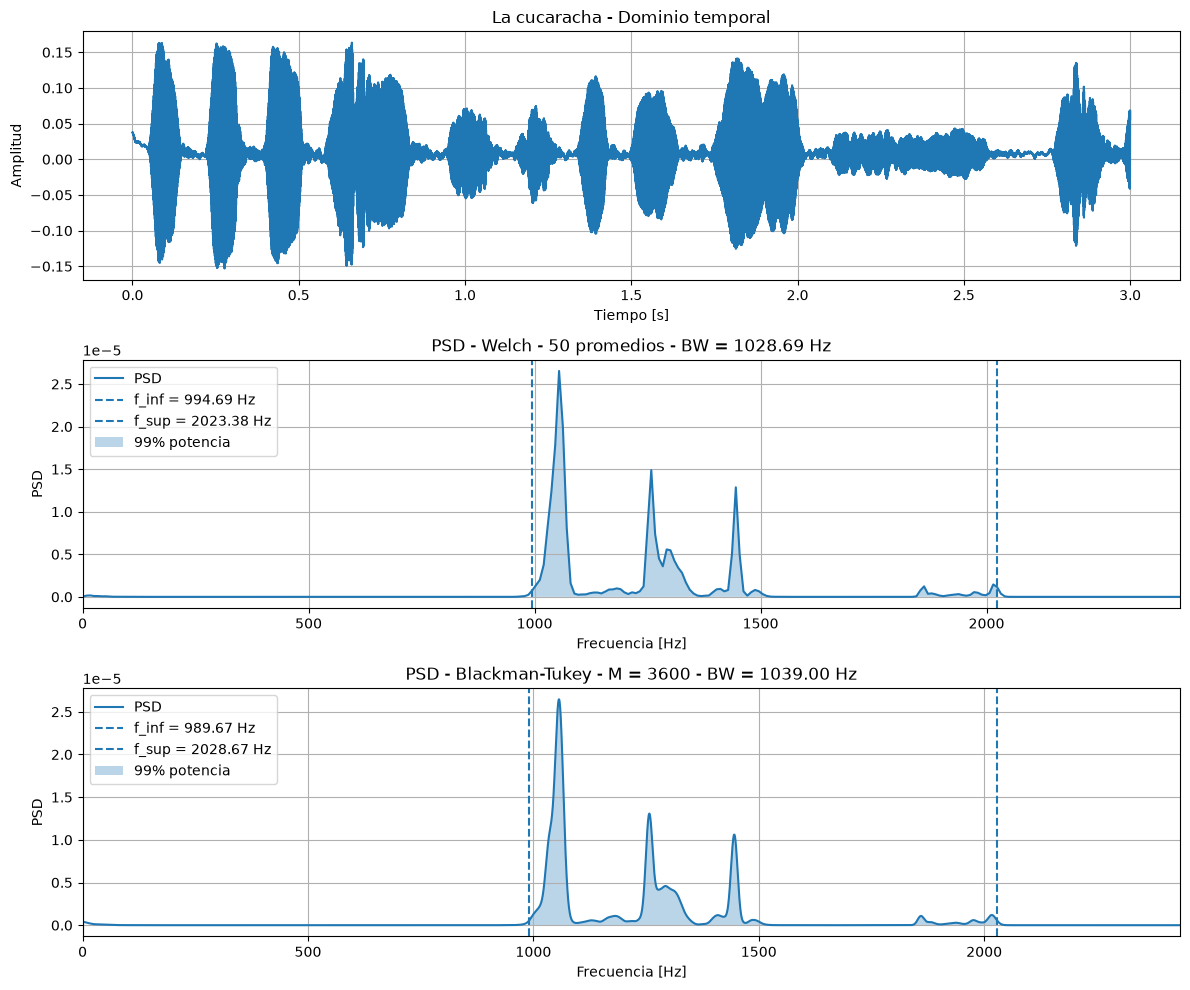

In [7]:
#%% AUDIO 1 - LA CUCARACHA

fs_audio1, audio1 = sio.wavfile.read('la cucaracha.wav')

# Si el audio tiene dos canales, lo pasamos a mono
if audio1.ndim > 1:
    audio1 = np.mean(audio1, axis=1)

audio1 = audio1.astype(float)

N_audio1 = len(audio1)
t_audio1 = np.arange(N_audio1) / fs_audio1

print('\nLA CUCARACHA')
print('Frecuencia de muestreo:', fs_audio1, 'Hz')
print('Cantidad de muestras:', N_audio1)
print('Duración:', N_audio1/fs_audio1, 's')

#%% AUDIO 1 - WELCH DEFINITIVO: 50 PROMEDIOS

nperseg_audio1 = nperseg_para_promedios(N_audio1, 50)
noverlap_audio1 = nperseg_audio1 // 2

f_welch_audio1, Pxx_welch_audio1 = sig.welch(
    audio1,
    fs=fs_audio1,
    window='hann',
    nperseg=nperseg_audio1,
    noverlap=noverlap_audio1,
    scaling='density'
)

K_audio1 = 1 + (N_audio1-nperseg_audio1)//(nperseg_audio1-noverlap_audio1)

BW_welch_audio1, f_welch_audio1_inf, f_welch_audio1_sup, \
i_welch_audio1, j_welch_audio1 = ancho_banda_audio(
    f_welch_audio1, Pxx_welch_audio1
)

print('Welch - cantidad de promedios:', K_audio1)
print('Welch - nperseg:', nperseg_audio1)

#%% AUDIO 1 - BLACKMAN TUKEY DEFINITIVO

M_audio1 = 3600

f_bt_audio1, Pxx_bt_audio1 = blackman_tukey(
    audio1,
    fs=fs_audio1,
    M=M_audio1,
    nfft=N_audio1
)

BW_bt_audio1, f_bt_audio1_inf, f_bt_audio1_sup, \
i_bt_audio1, j_bt_audio1 = ancho_banda_audio(
    f_bt_audio1, Pxx_bt_audio1
)


#%% FIGURA FINAL - LA CUCARACHA

fig, axs = plt.subplots(3, 1, figsize=(12, 10))

# Señal temporal
axs[0].plot(t_audio1, audio1)
axs[0].set_title('La cucaracha - Dominio temporal')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].grid()

# Welch
axs[1].plot(f_welch_audio1, Pxx_welch_audio1, label='PSD')
axs[1].axvline(f_welch_audio1_inf, ls='--',
               label=f'f_inf = {f_welch_audio1_inf:.2f} Hz')
axs[1].axvline(f_welch_audio1_sup, ls='--',
               label=f'f_sup = {f_welch_audio1_sup:.2f} Hz')
axs[1].fill_between(
    f_welch_audio1[i_welch_audio1:j_welch_audio1+1],
    Pxx_welch_audio1[i_welch_audio1:j_welch_audio1+1],
    alpha=0.3, label='99% potencia'
)
axs[1].set_title(
    f'PSD - Welch - {K_audio1} promedios - BW = {BW_welch_audio1:.2f} Hz'
)
axs[1].set_xlim(0, f_welch_audio1_sup*1.2)
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('PSD')
axs[1].grid()
axs[1].legend()

# Blackman-Tukey
axs[2].plot(f_bt_audio1, Pxx_bt_audio1, label='PSD')
axs[2].axvline(f_bt_audio1_inf, ls='--',
               label=f'f_inf = {f_bt_audio1_inf:.2f} Hz')
axs[2].axvline(f_bt_audio1_sup, ls='--',
               label=f'f_sup = {f_bt_audio1_sup:.2f} Hz')
axs[2].fill_between(
    f_bt_audio1[i_bt_audio1:j_bt_audio1+1],
    Pxx_bt_audio1[i_bt_audio1:j_bt_audio1+1],
    alpha=0.3, label='99% potencia'
)
axs[2].set_title(
    f'PSD - Blackman-Tukey - M = {M_audio1} - BW = {BW_bt_audio1:.2f} Hz'
)
axs[2].set_xlim(0, f_bt_audio1_sup*1.2)
axs[2].set_xlabel('Frecuencia [Hz]')
axs[2].set_ylabel('PSD')
axs[2].grid()
axs[2].legend()

plt.tight_layout()
plt.show()


En el dominio temporal se observó una amplitud variable a lo largo del registro debido a los distintos sonidos que formaron parte del audio. En frecuencia, la mayor parte de la potencia se concentró aproximadamente entre **$1$ kHz y $2$ kHz**, con un pico principal cercano a $1.05$ kHz y otras componentes de menor amplitud a frecuencias superiores.

Welch y Blackman-Tukey identificaron prácticamente la misma banda correspondiente al 99 % de la potencia espectral. Welch estimó un intervalo aproximado entre $995$ Hz y $2023$ Hz, mientras que Blackman-Tukey lo ubicó entre $990$ Hz y $2029$ Hz, obteniéndose en ambos casos un ancho de banda cercano a **$1.03$ kHz**.

### Audio 2: Prueba PSD

A continuación se analizó la señal **Prueba PSD** siguiendo el mismo procedimiento utilizado anteriormente. Para Welch se seleccionaron **60 promedios**, mientras que para Blackman-Tukey se utilizó **$M=3600$**. 


PRUEBA PSD
Frecuencia de muestreo: 48000 Hz
Cantidad de muestras: 144000
Duración: 3.0 s
Welch - cantidad de promedios: 60
Welch - nperseg: 4720


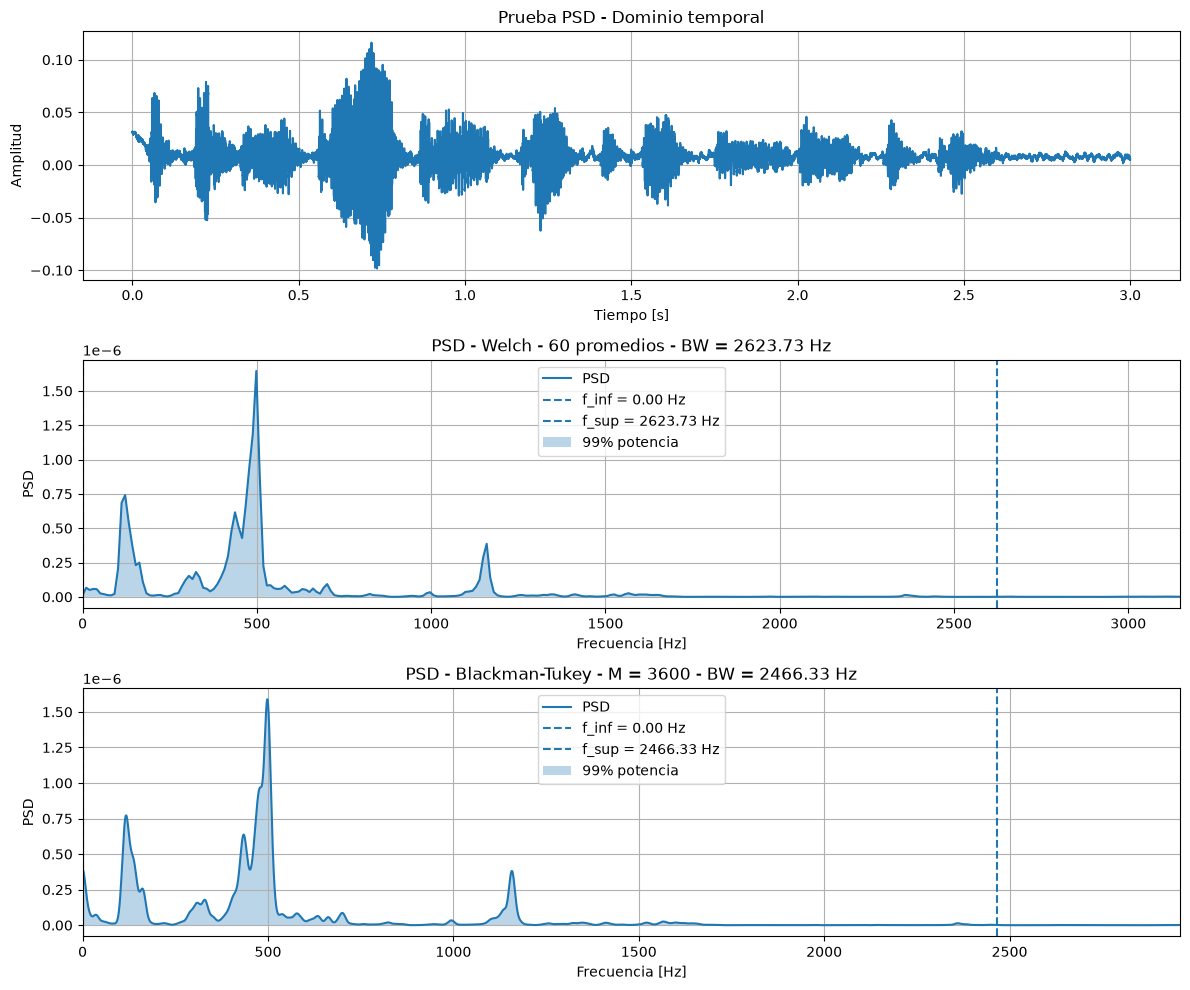

In [8]:
#%% AUDIO 2 - PRUEBA PSD

fs_audio2, audio2 = sio.wavfile.read('prueba psd.wav')

# Si tiene dos canales, lo pasamos a mono
if audio2.ndim > 1:
    audio2 = np.mean(audio2, axis=1)

audio2 = audio2.astype(float)

N_audio2 = len(audio2)
t_audio2 = np.arange(N_audio2) / fs_audio2

print('\nPRUEBA PSD')
print('Frecuencia de muestreo:', fs_audio2, 'Hz')
print('Cantidad de muestras:', N_audio2)
print('Duración:', N_audio2/fs_audio2, 's')

#%% AUDIO 2 - WELCH DEFINITIVO: 60 PROMEDIOS

nperseg_audio2 = nperseg_para_promedios(N_audio2, 60)
noverlap_audio2 = nperseg_audio2 // 2

f_welch_audio2, Pxx_welch_audio2 = sig.welch(
    audio2, fs=fs_audio2, window='hann',
    nperseg=nperseg_audio2, noverlap=noverlap_audio2,
    scaling='density'
)

K_audio2 = 1 + (N_audio2-nperseg_audio2)//(nperseg_audio2-noverlap_audio2)

BW_welch_audio2, f_welch_audio2_inf, f_welch_audio2_sup, \
i_welch_audio2, j_welch_audio2 = ancho_banda_audio(
    f_welch_audio2, Pxx_welch_audio2
)

print('Welch - cantidad de promedios:', K_audio2)
print('Welch - nperseg:', nperseg_audio2)

#%% AUDIO 2 - BLACKMAN TUKEY DEFINITIVO

M_audio2 = 3600

f_bt_audio2, Pxx_bt_audio2 = blackman_tukey(
    audio2, fs=fs_audio2, M=M_audio2, nfft=N_audio2
)

BW_bt_audio2, f_bt_audio2_inf, f_bt_audio2_sup, \
i_bt_audio2, j_bt_audio2 = ancho_banda_audio(
    f_bt_audio2, Pxx_bt_audio2
)

#%% FIGURA FINAL - PRUEBA PSD

fig, axs = plt.subplots(3, 1, figsize=(12,10))

axs[0].plot(t_audio2, audio2)
axs[0].set_title('Prueba PSD - Dominio temporal')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].grid()

axs[1].plot(f_welch_audio2, Pxx_welch_audio2, label='PSD')
axs[1].axvline(f_welch_audio2_inf, ls='--', label=f'f_inf = {f_welch_audio2_inf:.2f} Hz')
axs[1].axvline(f_welch_audio2_sup, ls='--', label=f'f_sup = {f_welch_audio2_sup:.2f} Hz')
axs[1].fill_between(f_welch_audio2[i_welch_audio2:j_welch_audio2+1],
                    Pxx_welch_audio2[i_welch_audio2:j_welch_audio2+1],
                    alpha=0.3, label='99% potencia')
axs[1].set_title(f'PSD - Welch - {K_audio2} promedios - BW = {BW_welch_audio2:.2f} Hz')
axs[1].set_xlim(0, f_welch_audio2_sup*1.2)
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('PSD')
axs[1].grid()
axs[1].legend()

axs[2].plot(f_bt_audio2, Pxx_bt_audio2, label='PSD')
axs[2].axvline(f_bt_audio2_inf, ls='--', label=f'f_inf = {f_bt_audio2_inf:.2f} Hz')
axs[2].axvline(f_bt_audio2_sup, ls='--', label=f'f_sup = {f_bt_audio2_sup:.2f} Hz')
axs[2].fill_between(f_bt_audio2[i_bt_audio2:j_bt_audio2+1],
                    Pxx_bt_audio2[i_bt_audio2:j_bt_audio2+1],
                    alpha=0.3, label='99% potencia')
axs[2].set_title(f'PSD - Blackman-Tukey - M = {M_audio2} - BW = {BW_bt_audio2:.2f} Hz')
axs[2].set_xlim(0, f_bt_audio2_sup*1.2)
axs[2].set_xlabel('Frecuencia [Hz]')
axs[2].set_ylabel('PSD')
axs[2].grid()
axs[2].legend()

plt.tight_layout()
plt.show()


Al igual que en el audio anterior, ambos métodos conservaron las principales componentes espectrales y mostraron una distribución de potencia similar, con varios picos claramente definidos.

En este caso, el intervalo que contenía el 99 % de la potencia espectral comenzó en $0$ Hz, debido a la presencia de contenido relevante en las bajas frecuencias. Además, se observó una diferencia algo mayor entre los anchos de banda estimados por ambos métodos, obteniéndose aproximadamente **$2.62$ kHz para Welch** y **$2.47$ kHz para Blackman-Tukey**.

### Audio 3: Silbido

Finalmente se analizó la señal correspondiente a **Silbido**. Para Welch se seleccionaron **70 promedios**, mientras que para Blackman-Tukey se utilizó **$M=3600$**. 


SILBIDO
Frecuencia de muestreo: 48000 Hz
Cantidad de muestras: 144000
Duración: 3.0 s
Welch - cantidad de promedios: 70
Welch - nperseg: 4056


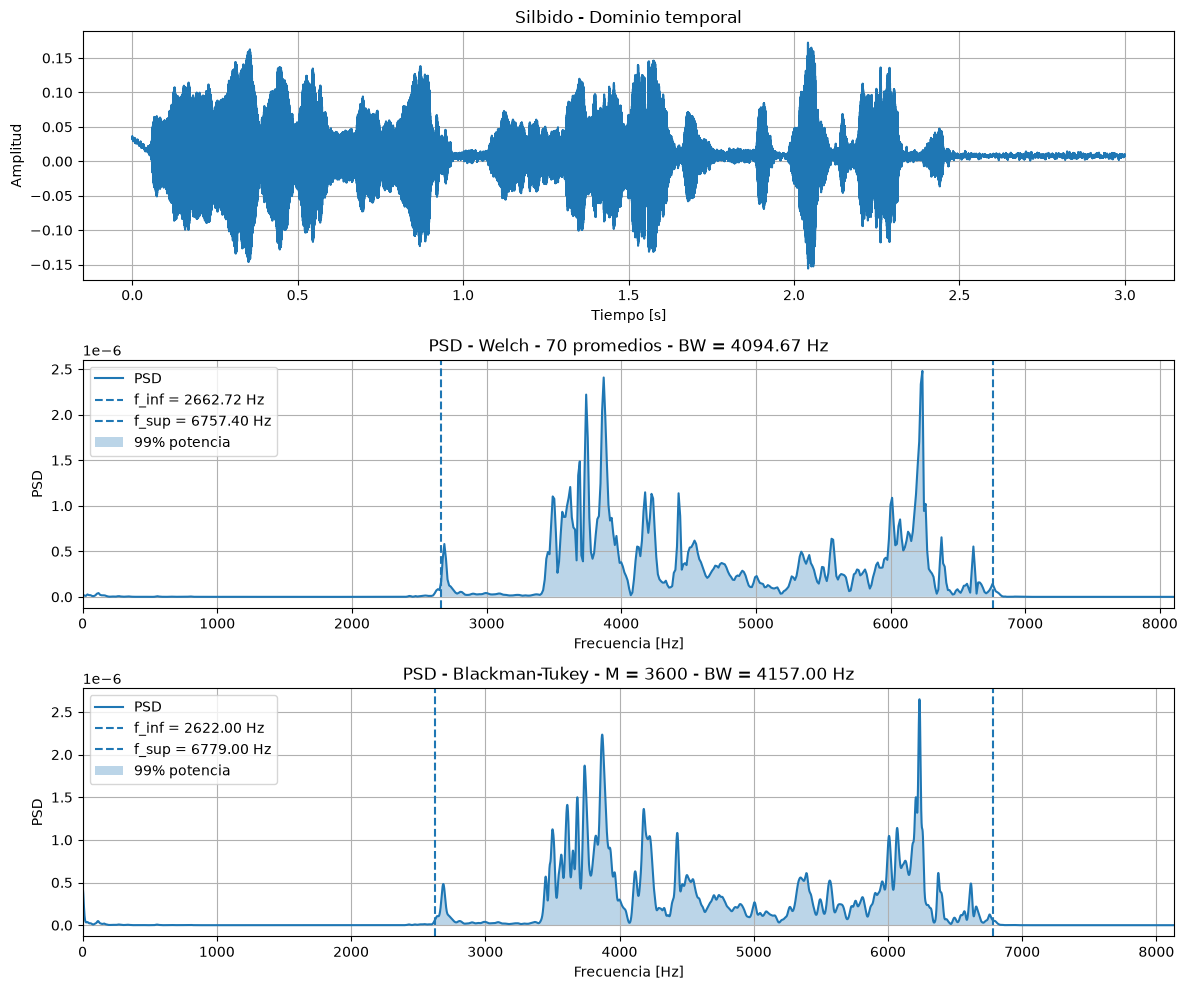

In [9]:
#%% AUDIO 3 - SILBIDO

fs_audio3, audio3 = sio.wavfile.read('silbido.wav')

# Si tiene dos canales, lo pasamos a mono
if audio3.ndim > 1:
    audio3 = np.mean(audio3, axis=1)

audio3 = audio3.astype(float)

N_audio3 = len(audio3)
t_audio3 = np.arange(N_audio3) / fs_audio3

print('\nSILBIDO')
print('Frecuencia de muestreo:', fs_audio3, 'Hz')
print('Cantidad de muestras:', N_audio3)
print('Duración:', N_audio3/fs_audio3, 's')

#%% AUDIO 3 - WELCH DEFINITIVO: 70 PROMEDIOS

nperseg_audio3 = nperseg_para_promedios(N_audio3, 70)
noverlap_audio3 = nperseg_audio3 // 2

f_welch_audio3, Pxx_welch_audio3 = sig.welch(
    audio3,
    fs=fs_audio3,
    window='hann',
    nperseg=nperseg_audio3,
    noverlap=noverlap_audio3,
    scaling='density'
)

K_audio3 = 1 + (N_audio3-nperseg_audio3)//(nperseg_audio3-noverlap_audio3)

BW_welch_audio3, f_welch_audio3_inf, f_welch_audio3_sup, \
i_welch_audio3, j_welch_audio3 = ancho_banda_audio(
    f_welch_audio3, Pxx_welch_audio3
)

print('Welch - cantidad de promedios:', K_audio3)
print('Welch - nperseg:', nperseg_audio3)

#%% AUDIO 3 - BLACKMAN TUKEY DEFINITIVO

M_audio3 = 3600

f_bt_audio3, Pxx_bt_audio3 = blackman_tukey(
    audio3,
    fs=fs_audio3,
    M=M_audio3,
    nfft=N_audio3
)

BW_bt_audio3, f_bt_audio3_inf, f_bt_audio3_sup, \
i_bt_audio3, j_bt_audio3 = ancho_banda_audio(
    f_bt_audio3, Pxx_bt_audio3
)

#%% FIGURA FINAL - SILBIDO

fig, axs = plt.subplots(3, 1, figsize=(12,10))

# Señal temporal
axs[0].plot(t_audio3, audio3)
axs[0].set_title('Silbido - Dominio temporal')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].grid()

# Welch
axs[1].plot(f_welch_audio3, Pxx_welch_audio3, label='PSD')
axs[1].axvline(f_welch_audio3_inf, ls='--',
               label=f'f_inf = {f_welch_audio3_inf:.2f} Hz')
axs[1].axvline(f_welch_audio3_sup, ls='--',
               label=f'f_sup = {f_welch_audio3_sup:.2f} Hz')
axs[1].fill_between(
    f_welch_audio3[i_welch_audio3:j_welch_audio3+1],
    Pxx_welch_audio3[i_welch_audio3:j_welch_audio3+1],
    alpha=0.3, label='99% potencia'
)
axs[1].set_title(
    f'PSD - Welch - {K_audio3} promedios - BW = {BW_welch_audio3:.2f} Hz'
)
axs[1].set_xlim(0, f_welch_audio3_sup*1.2)
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('PSD')
axs[1].grid()
axs[1].legend()

# Blackman-Tukey
axs[2].plot(f_bt_audio3, Pxx_bt_audio3, label='PSD')
axs[2].axvline(f_bt_audio3_inf, ls='--',
               label=f'f_inf = {f_bt_audio3_inf:.2f} Hz')
axs[2].axvline(f_bt_audio3_sup, ls='--',
               label=f'f_sup = {f_bt_audio3_sup:.2f} Hz')
axs[2].fill_between(
    f_bt_audio3[i_bt_audio3:j_bt_audio3+1],
    Pxx_bt_audio3[i_bt_audio3:j_bt_audio3+1],
    alpha=0.3, label='99% potencia'
)
axs[2].set_title(
    f'PSD - Blackman-Tukey - M = {M_audio3} - BW = {BW_bt_audio3:.2f} Hz'
)
axs[2].set_xlim(0, f_bt_audio3_sup*1.2)
axs[2].set_xlabel('Frecuencia [Hz]')
axs[2].set_ylabel('PSD')
axs[2].grid()
axs[2].legend()

plt.tight_layout()
plt.show()


Nuevamente, las estimaciones de Welch y Blackman-Tukey presentaron una distribución espectral muy similar. En este caso, la potencia se concentró en una banda claramente alejada de $0$ Hz, aproximadamente entre $2.6$ kHz y $6.8$ kHz.

Ambos métodos estimaron prácticamente el mismo ancho de banda, obteniéndose valores cercanos a **$4.1$ kHz**, por lo que identificaron de manera coincidente la región que contenía el 99 % de la potencia espectral.

## Comparación de los resultados del ancho de banda
Posteriormente, se realizó una tabla comparativa con los anchos de banda obtenidos para las distintas señales analizadas mediante Welch y Blackman-Tukey.

In [7]:
#%% TABLA FINAL DE RESULTADOS

resultados = [
    ['ECG', 'Welch', f_welch_inf, f_welch_sup, BW_welch_ecg],
    ['ECG', 'Blackman-Tukey', f_bt_inf, f_bt_sup, BW_bt_ecg],

    ['PPG', 'Welch', f_welch_ppg_inf, f_welch_ppg_sup, BW_welch_ppg],
    ['PPG', 'Blackman-Tukey', f_bt_ppg_inf, f_bt_ppg_sup, BW_bt_ppg],

    ['La cucaracha', 'Welch', f_welch_audio1_inf, f_welch_audio1_sup, BW_welch_audio1],
    ['La cucaracha', 'Blackman-Tukey', f_bt_audio1_inf, f_bt_audio1_sup, BW_bt_audio1],

    ['Prueba PSD', 'Welch', f_welch_audio2_inf, f_welch_audio2_sup, BW_welch_audio2],
    ['Prueba PSD', 'Blackman-Tukey', f_bt_audio2_inf, f_bt_audio2_sup, BW_bt_audio2],

    ['Silbido', 'Welch', f_welch_audio3_inf, f_welch_audio3_sup, BW_welch_audio3],
    ['Silbido', 'Blackman-Tukey', f_bt_audio3_inf, f_bt_audio3_sup, BW_bt_audio3]
]

print('\nRESULTADOS FINALES\n')

print(f'{"Señal":<16} {"Método":<18} {"f_inf [Hz]":>12} {"f_sup [Hz]":>12} {"BW [Hz]":>12}')
print('-'*75)

for fila in resultados:
    señal, metodo, f_inf, f_sup, BW = fila

    print(f'{señal:<16} {metodo:<18} '
          f'{f_inf:>12.2f} {f_sup:>12.2f} {BW:>12.2f}')
    


RESULTADOS FINALES

Señal            Método               f_inf [Hz]   f_sup [Hz]      BW [Hz]
---------------------------------------------------------------------------
ECG              Welch                      0.00        30.45        30.45
ECG              Blackman-Tukey             0.00        30.87        30.87
PPG              Welch                      0.00         5.44         5.44
PPG              Blackman-Tukey             0.00         5.42         5.42
La cucaracha     Welch                    994.69      2023.38      1028.69
La cucaracha     Blackman-Tukey           989.67      2028.67      1039.00
Prueba PSD       Welch                      0.00      2623.73      2623.73
Prueba PSD       Blackman-Tukey             0.00      2466.33      2466.33
Silbido          Welch                   2662.72      6757.40      4094.67
Silbido          Blackman-Tukey          2622.00      6779.00      4157.00


A partir de los resultados obtenidos se observaron diferencias claras entre los distintos tipos de señales. El **ECG y el PPG** concentraron su potencia principalmente en bajas frecuencias, con anchos de banda de aproximadamente $30$ Hz y $5.4$ Hz, respectivamente. En cambio, las señales de **audio** presentaron contenido en frecuencias considerablemente mayores: *La cucaracha* concentró la mayor parte de su potencia aproximadamente entre $1$ kHz y $2$ kHz, mientras que *Silbido* lo hizo entre $2.6$ kHz y $6.8$ kHz.

Estos resultados mostraron también que, para las señales de audio, no siempre correspondió fijar $f_{\mathrm{inf}}=0$ Hz. Sin embargo, *Prueba PSD* constituyó una excepción, ya que presentó contenido relevante desde las bajas frecuencias y su banda comenzó en $0$ Hz.

En términos generales, **Welch y Blackman-Tukey proporcionaron valores de ancho de banda muy similares**. La mayor diferencia se observó para *Prueba PSD*, donde Welch estimó un límite superior algo mayor. Estas diferencias pueden asociarse al distinto suavizado introducido por cada estimador y al criterio del 99 % de la potencia, ya que pequeñas variaciones en componentes de baja amplitud pueden modificar los límites de la banda estimada.

En conjunto, ambos métodos permitieron obtener resultados comparables para las distintas señales analizadas.


## Bonus: Electromiograma (EMG)

Para realizar el bonus se seleccionó una señal de **electromiografía (EMG)**. El EMG registra la actividad eléctrica asociada a la activación muscular y puede utilizarse para evaluar el funcionamiento de los músculos y de los nervios que los controlan.

La señal utilizada fue obtenida de la base de datos abierta *Examples of Electromyograms de PhysioNet*, utilizando específicamente el registro `emg_healthy`. Este correspondió a un hombre de 44 años sin antecedentes de enfermedad neuromuscular.

La señal fue registrada originalmente con una frecuencia de muestreo de $50$ kHz y posteriormente submuestreada a: $f_s=4\text{ kHz}$

Fuente: [PhysioNet - Examples of Electromyograms](https://physionet.org/content/emgdb/1.0.0/)

Se estimó la PSD mediante Welch y Blackman-Tukey. Para Welch se utilizó una **ventana Hann** y se seleccionaron **70 promedios**, mientras que para Blackman-Tukey se utilizó **$M=1271$**. Finalmente, se determinó el ancho de banda correspondiente al 99 % de la potencia espectral.

Welch - cantidad de promedios: 70
Welch - nperseg: 1432


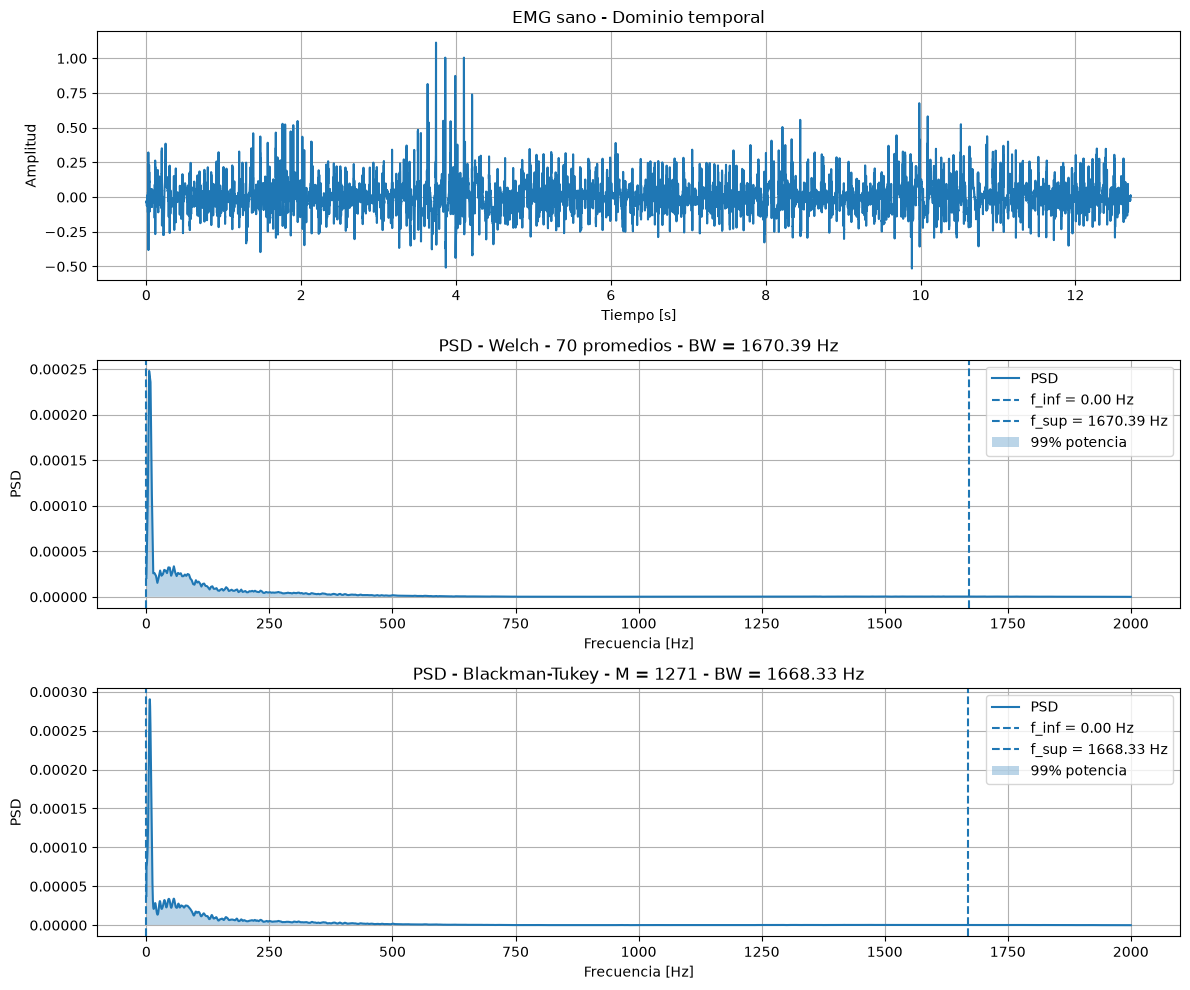


ANCHO DE BANDA - EMG SANO
Welch:
  f_inf = 0.00 Hz
  f_sup = 1670.39 Hz
  BW    = 1670.39 Hz

Blackman-Tukey:
  f_inf = 0.00 Hz
  f_sup = 1668.33 Hz
  BW    = 1668.33 Hz
Hasta 100.6 Hz: 63.50 % de la potencia
Hasta 248.6 Hz: 81.61 % de la potencia
Hasta 500.0 Hz: 93.02 % de la potencia
Hasta 748.6 Hz: 95.58 % de la potencia
Hasta 1000.0 Hz: 96.22 % de la potencia
Hasta 1248.6 Hz: 96.95 % de la potencia
Hasta 1500.0 Hz: 98.12 % de la potencia
Hasta 1670.4 Hz: 99.01 % de la potencia


In [9]:
#%% BONUS - EMG SANO

fs_emg = 4000  # Hz

datos_emg = np.genfromtxt(
    'emg_healthy.txt',
    delimiter=None,      # detecta espacios o tabulaciones
    encoding='latin1',
    invalid_raise=False
)

# Eliminamos posibles filas no numéricas
if datos_emg.ndim == 2:
    datos_emg = datos_emg[np.all(np.isfinite(datos_emg), axis=1)]

t_emg = datos_emg[:,0]
emg = datos_emg[:,1]

N_emg = len(emg)

#%% BONUS EMG - WELCH DEFINITIVO

nperseg_emg = nperseg_para_promedios(N_emg, 70)
noverlap_emg = nperseg_emg // 2

f_welch_emg, Pxx_welch_emg = sig.welch(
    emg, fs=fs_emg, window='hann',
    nperseg=nperseg_emg, noverlap=noverlap_emg,
    scaling='density'
)

K_emg = 1 + (N_emg-nperseg_emg)//(nperseg_emg-noverlap_emg)

BW_welch_emg, f_welch_emg_inf, f_welch_emg_sup, \
i_welch_emg, j_welch_emg = ancho_banda_audio(
    f_welch_emg, Pxx_welch_emg
)

print('Welch - cantidad de promedios:', K_emg)
print('Welch - nperseg:', nperseg_emg)

#%% BONUS EMG - BLACKMAN TUKEY DEFINITIVO

M_emg = 1271

f_bt_emg, Pxx_bt_emg = blackman_tukey(
    emg, fs=fs_emg, M=M_emg, nfft=N_emg
)

BW_bt_emg, f_bt_emg_inf, f_bt_emg_sup, \
i_bt_emg, j_bt_emg = ancho_banda_audio(
    f_bt_emg, Pxx_bt_emg
)

#%% FIGURA FINAL - EMG SANO

fig, axs = plt.subplots(3, 1, figsize=(12,10))

axs[0].plot(t_emg, emg)
axs[0].set_title('EMG sano - Dominio temporal')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].grid()

axs[1].plot(f_welch_emg, Pxx_welch_emg, label='PSD')
axs[1].axvline(f_welch_emg_inf, ls='--',
               label=f'f_inf = {f_welch_emg_inf:.2f} Hz')
axs[1].axvline(f_welch_emg_sup, ls='--',
               label=f'f_sup = {f_welch_emg_sup:.2f} Hz')
axs[1].fill_between(
    f_welch_emg[i_welch_emg:j_welch_emg+1],
    Pxx_welch_emg[i_welch_emg:j_welch_emg+1],
    alpha=0.3, label='99% potencia'
)
axs[1].set_title(
    f'PSD - Welch - {K_emg} promedios - BW = {BW_welch_emg:.2f} Hz'
)
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('PSD')
axs[1].grid()
axs[1].legend()

axs[2].plot(f_bt_emg, Pxx_bt_emg, label='PSD')
axs[2].axvline(f_bt_emg_inf, ls='--',
               label=f'f_inf = {f_bt_emg_inf:.2f} Hz')
axs[2].axvline(f_bt_emg_sup, ls='--',
               label=f'f_sup = {f_bt_emg_sup:.2f} Hz')
axs[2].fill_between(
    f_bt_emg[i_bt_emg:j_bt_emg+1],
    Pxx_bt_emg[i_bt_emg:j_bt_emg+1],
    alpha=0.3, label='99% potencia'
)
axs[2].set_title(
    f'PSD - Blackman-Tukey - M = {M_emg} - BW = {BW_bt_emg:.2f} Hz'
)
axs[2].set_xlabel('Frecuencia [Hz]')
axs[2].set_ylabel('PSD')
axs[2].grid()
axs[2].legend()

plt.tight_layout()
plt.show()
#%% RESULTADOS BONUS EMG

print('\nANCHO DE BANDA - EMG SANO')

print(f'Welch:')
print(f'  f_inf = {f_welch_emg_inf:.2f} Hz')
print(f'  f_sup = {f_welch_emg_sup:.2f} Hz')
print(f'  BW    = {BW_welch_emg:.2f} Hz')

print(f'\nBlackman-Tukey:')
print(f'  f_inf = {f_bt_emg_inf:.2f} Hz')
print(f'  f_sup = {f_bt_emg_sup:.2f} Hz')
print(f'  BW    = {BW_bt_emg:.2f} Hz')

#%% POTENCIA ACUMULADA EMG

df = f_welch_emg[1] - f_welch_emg[0]
potencia_acum = np.cumsum(Pxx_welch_emg) * df
potencia_acum /= potencia_acum[-1]

for freq in [100, 250, 500, 750, 1000, 1250, 1500, 1670]:
    i = np.argmin(np.abs(f_welch_emg - freq))
    print(f'Hasta {f_welch_emg[i]:.1f} Hz: '
          f'{potencia_acum[i]*100:.2f} % de la potencia')

Nuevamente, Welch y Blackman-Tukey produjeron estimaciones muy similares. La mayor parte de la potencia se concentró en las bajas frecuencias, aunque se observó una componente de menor amplitud distribuida sobre un rango frecuencial considerablemente amplio.

El análisis de potencia acumulada mostró que aproximadamente el **63.5 %** de la potencia se encontraba por debajo de $100$ Hz, el **81.6 %** por debajo de $250$ Hz y el **93.0 %** por debajo de $500$ Hz. Sin embargo, para alcanzar el **99 % de la potencia** fue necesario extender la banda hasta aproximadamente $1.67$ kHz.

Los anchos de banda obtenidos fueron:

$$BW_{\mathrm{Welch}}=1670.39\text{ Hz}$$

$$BW_{\mathrm{BT}}=1668.33\text{ Hz}$$

La similitud entre ambos valores mostró una buena concordancia entre los estimadores. Además, este resultado evidenció que el ancho de banda determinado mediante potencia acumulada no depende únicamente de los picos de mayor amplitud, ya que componentes pequeñas distribuidas en frecuencias más altas también contribuyeron a la potencia total.


## Conclusión
A lo largo del trabajo se analizaron distintas señales reales mediante estimación espectral, comparando inicialmente el **periodograma modificado**, **Welch** y **Blackman-Tukey**. Se observó que el periodograma modificado presentó una varianza considerablemente mayor, mientras que Welch y Blackman-Tukey produjeron estimaciones más suaves, por lo que fueron los métodos utilizados para el resto de las señales.

La selección de los parámetros de ambos estimadores se realizó buscando un compromiso entre **reducción de varianza y conservación de la resolución espectral**. En particular, cuando no se conoce previamente la PSD de una señal, resultó importante comenzar con una estimación de mayor varianza y reducirla progresivamente, aumentando la cantidad de promedios en Welch o disminuyendo $M$ en Blackman-Tukey, siempre verificando que no se perdieran picos o componentes espectrales relevantes.

El análisis del ancho de banda mostró diferencias claras entre los distintos tipos de señales. El *ECG y el PPG* concentraron su potencia en bajas frecuencias, mientras que las señales de *audio* presentaron contenido espectral en bandas considerablemente más altas y, en algunos casos, alejadas de $0$ Hz. En general, Welch y Blackman-Tukey proporcionaron resultados muy similares para el ancho de banda, mostrando una buena concordancia entre ambos métodos.

